# 02 · Verificación de la limpieza

El script `src/limpieza/fincaraiz.py` aplicó las reglas. Este notebook **comprueba** que el resultado
tiene sentido. Limpiar sin verificar es tan riesgoso como no limpiar: una regla mal escrita puede
borrar datos buenos sin que nadie se dé cuenta.

Verificamos cuatro cosas:
1. Cuánto afectó cada regla.
2. Que las distribuciones ya no tengan valores imposibles.
3. Que los datos se comporten como esperamos del mundo real (*sanity checks*).
4. Si faltan precios intermedios por el tope de 10.000 resultados (el sesgo que acordamos medir).

In [21]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid")

RAIZ = Path.cwd()
while not (RAIZ / "requirements.txt").exists():
    RAIZ = RAIZ.parent

interim = RAIZ / "data" / "interim"
limpio_path = sorted(interim.glob("fincaraiz_limpio_*.csv"))[-1]
fecha = limpio_path.stem.replace("fincaraiz_limpio_", "")
crudo = pd.read_csv(interim / f"fincaraiz_{fecha}.csv", dtype={"id": str})
df = pd.read_csv(limpio_path, dtype={"id": str})
print(f"Antes: {len(crudo):,} anuncios  |  Después: {len(df):,}  |  Fecha de la corrida: {fecha}")

Antes: 31,675 anuncios  |  Después: 31,549  |  Fecha de la corrida: 2026-10-23


## 1. Impacto de cada regla

Esta tabla también va al artículo, en la sección de metodología: documenta exactamente qué se hizo con los datos.

In [22]:
reglas = pd.read_csv(RAIZ / "reports" / f"limpieza_fincaraiz_{fecha}.csv")
reglas["% del total"] = (reglas["afectados"] / len(crudo) * 100).round(2)
reglas

,regla,descripcion,accion,afectados,% del total
0,1,Municipio fuera del Valle de Aburrá,eliminar fila,40,0.13
1,2,"Precio fuera de $300,000 - $100,000,000",eliminar fila,22,0.07
2,3,Nombre de municipio normalizado,corregir,1434,4.53
3,4,Área fuera de 15-1000 m²,faltante (area_m2),371,1.17
4,5,"Precio por m² fuera de $10,000 - $200,000",eliminar fila,64,0.20
5,6,"Habitaciones <0, >10, o 0 sin ser apartaestudio",faltante (habitaciones),287,0.91
6,7,Baños 0 o >10,faltante (banos),193,0.61
7,8,Parqueaderos <0 o >10 (el 0 es real y se conse...,faltante (parqueaderos),46,0.15
8,9,"Piso 0 (no informado), negativo o >45",faltante (piso),18032,56.93
9,10,Estrato fuera de 1-6,faltante (estrato),294,0.93


## 2. Resumen estadístico después de limpiar

Compara con la tabla del notebook 01: el mínimo y el máximo de cada columna ahora deben ser **valores posibles**.

In [23]:
numericas = ["precio", "area_m2", "habitaciones", "banos", "parqueaderos", "piso", "estrato"]
df[numericas].describe(percentiles=[0.01, 0.5, 0.99]).T

,count,mean,std,min,1%,50%,99%,max
precio,"31,549.00","5,749,978.80","4,918,578.70","450,000.00","1,254,800.00","4,300,000.00","26,000,000.00","90,000,000.00"
area_m2,"30,354.00",119.40,96.76,15.00,25.00,88.00,500.00,"1,000.00"
habitaciones,"31,262.00",2.67,0.99,0.00,1.00,3.00,6.00,10.00
banos,"31,356.00",2.52,1.11,1.00,1.00,2.00,6.00,10.00
parqueaderos,"31,503.00",1.27,1.07,0.00,0.00,1.00,5.00,10.00
piso,"13,056.00",7.70,6.41,1.00,1.00,6.00,22.00,32.00
estrato,"31,490.00",4.83,1.04,2.00,2.00,5.00,6.00,6.00


In [24]:
print("ANUNCIOS POR MUNICIPIO\n", df["municipio"].value_counts().to_string(), "\n")
print("ANUNCIOS POR TIPO\n", df["tipo_inmueble"].value_counts().to_string(), "\n")
print("Estratos estimados con la moda del barrio:", int(df["estrato_imputado"].sum()))

ANUNCIOS POR MUNICIPIO
 municipio
Medellín       18931
Envigado        6998
Sabaneta        3284
Bello            820
Itagüí           727
La Estrella      705
Copacabana        48
Caldas            23
Girardota          7
Barbosa            6 

ANUNCIOS POR TIPO
 tipo_inmueble
Apartamento      25531
Casa              4105
Apartaestudio     1881
Habitación          32 

Estratos estimados con la moda del barrio: 269


## 3. Sanity checks: ¿los datos se comportan como el mundo real?

Si los datos están bien, deberíamos ver patrones que ya sabemos que existen:

- **El precio sube con el estrato.** Lo vemos con un **diagrama de caja** (*boxplot*): la línea del medio
  es la mediana, la caja contiene el 50 % central de los anuncios y los puntos sueltos son valores atípicos.
- **El precio sube con el área.**
- **Las coordenadas dibujan la forma del valle** (alargado de sur a norte, siguiendo el río).

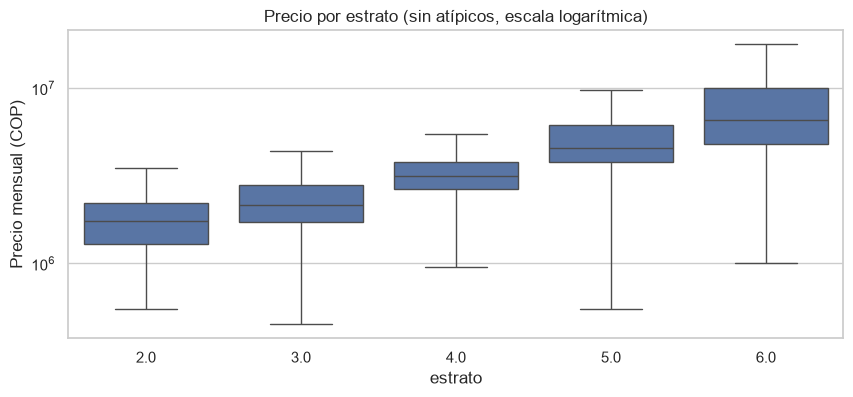

estrato
2.00    $1,750,000
3.00    $2,150,000
4.00    $3,150,000
5.00    $4,550,000
6.00    $6,600,000


In [25]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(data=df, x="estrato", y="precio", ax=ax, showfliers=False)
ax.set_yscale("log")
ax.set_title("Precio por estrato (sin atípicos, escala logarítmica)")
ax.set_ylabel("Precio mensual (COP)")
plt.show()
print(df.groupby("estrato")["precio"].median().map("${:,.0f}".format).to_string())

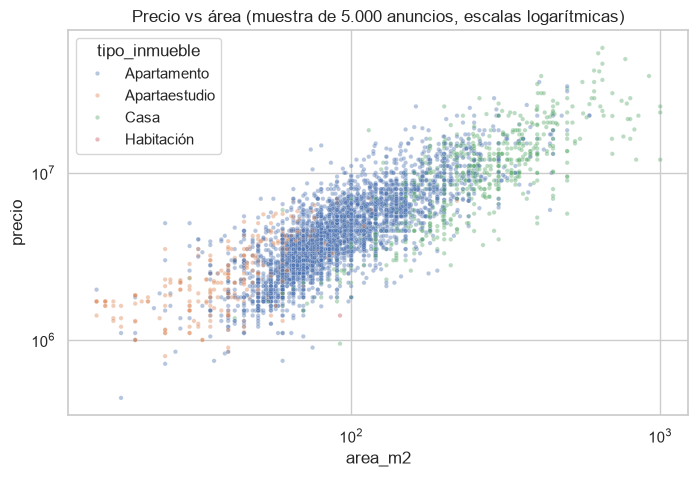

Correlación entre log(área) y log(precio): 0.845


In [26]:
fig, ax = plt.subplots(figsize=(8, 5))
muestra = df.dropna(subset=["area_m2"]).sample(min(5000, len(df)), random_state=42)
sns.scatterplot(data=muestra, x="area_m2", y="precio", hue="tipo_inmueble", s=10, alpha=0.4, ax=ax)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_title("Precio vs área (muestra de 5.000 anuncios, escalas logarítmicas)")
plt.show()
print("Correlación entre log(área) y log(precio):",
      round(np.log(df["area_m2"]).corr(np.log(df["precio"])), 3))

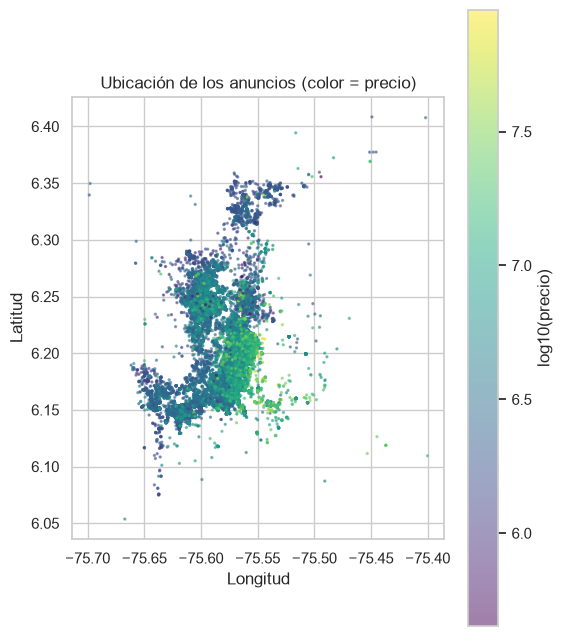

In [27]:
fig, ax = plt.subplots(figsize=(6, 8))
geo = df.dropna(subset=["lat", "lon"])
sc = ax.scatter(geo["lon"], geo["lat"], c=np.log10(geo["precio"]), s=2, cmap="viridis", alpha=0.5)
ax.set_title("Ubicación de los anuncios (color = precio)")
ax.set_xlabel("Longitud"); ax.set_ylabel("Latitud"); ax.set_aspect("equal")
plt.colorbar(sc, label="log10(precio)")
plt.show()

## 4. ¿Faltan precios intermedios? (sesgo por el tope de 10.000)

En Medellín/apartamentos el sitio solo mostró 10.000 resultados por orden. Completamos con los barridos
"baratos" y "lujosos", que cubren los **extremos** de precio. El riesgo: que falten anuncios del **medio**.

**Cómo lo medimos:** el barrido por **popularidad** mezcla todos los precios, así que lo usamos como
**muestra de referencia**. Si el dataset final tiene la misma forma de precios que la referencia,
no hay sesgo. Si el final tiene *menos* proporción en el medio, el sesgo existe.

*Limitación de esta prueba:* la popularidad podría estar algo relacionada con el precio; es la mejor
referencia disponible, no una perfecta.

In [28]:
# IDs vistos en el barrido por popularidad (archivos SIN 'baratos'/'lujosos' en el nombre)
carpeta_raw = RAIZ / "data" / "raw" / "fincaraiz" / fecha
ids_ref = set()
for f in carpeta_raw.glob("medellin__apartamentos__p*.json"):
    ids_ref |= {str(a["id"]) for a in json.loads(f.read_text(encoding="utf-8"))["data"]}

aptos = df[(df["municipio"] == "Medellín") & (df["tipo_inmueble"] == "Apartamento")]
ref = aptos[aptos["id"].isin(ids_ref)]
print(f"Referencia (popularidad): {len(ref):,}  |  Dataset final: {len(aptos):,}")

q = [0.10, 0.25, 0.50, 0.75, 0.90]
comparacion = pd.DataFrame({
    "referencia": ref["precio"].quantile(q),
    "final": aptos["precio"].quantile(q),
})
comparacion["diferencia %"] = ((comparacion["final"] / comparacion["referencia"] - 1) * 100).round(1)
comparacion.index = [f"percentil {int(x*100)}" for x in q]
comparacion

Referencia (popularidad): 9,677  |  Dataset final: 14,833


,referencia,final,diferencia %
percentil 10,"2,500,000.00","2,500,000.00",0.00
percentil 25,"3,600,000.00","3,600,000.00",0.00
percentil 50,"4,900,000.00","4,900,000.00",0.00
percentil 75,"7,000,000.00","7,000,000.00",0.00
percentil 90,"10,000,000.00","10,000,000.00",0.00


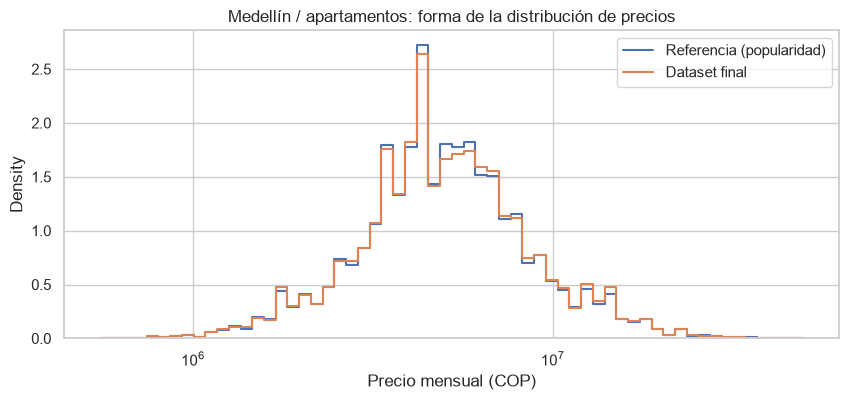

In [29]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.histplot(ref["precio"], bins=60, log_scale=True, stat="density", element="step", fill=False, label="Referencia (popularidad)", ax=ax)
sns.histplot(aptos["precio"], bins=60, log_scale=True, stat="density", element="step", fill=False, label="Dataset final", ax=ax)
ax.set_title("Medellín / apartamentos: forma de la distribución de precios")
ax.set_xlabel("Precio mensual (COP)")
ax.legend()
plt.show()

**Cómo leer el resultado:** si las dos curvas casi se superponen y las diferencias por percentil son
pequeñas (menos de ~5 %), el hueco no sesga los precios y basta con declararlo como limitación.
Si el dataset final tiene un "valle" en el centro que la referencia no tiene, aplicamos la división
por habitaciones en el scraper.

In [30]:
cols = ["tipo_inmueble", "municipio", "barrio", "precio", "area_m2", "estrato", "estrato_imputado", "url"]

# A) Anuncios de estrato 1
e1 = df[df["estrato"] == 1]
print(f"A) {len(e1)} anuncios de estrato 1. Barrios más comunes:")
print(e1["barrio"].value_counts().head(10).to_string())
display(e1[cols].sort_values("precio", ascending=False).head(10))

# B) Precio por m²: los extremos
df["precio_m2"] = df["precio"] / df["area_m2"]
print("\nB) Precio por m²:")
print(df["precio_m2"].describe(percentiles=[0.005, 0.01, 0.5, 0.99, 0.995]).to_string())
display(df.nsmallest(5, "precio_m2")[cols + ["precio_m2"]])
display(df.nlargest(5, "precio_m2")[cols + ["precio_m2"]])

# Los 5 más caros después de limpiar (¿el de $90 millones es real?)
display(df.nlargest(5, "precio")[cols])

A) 0 anuncios de estrato 1. Barrios más comunes:
Series([], )


,tipo_inmueble,municipio,barrio,precio,area_m2,estrato,estrato_imputado,url



B) Precio por m²:
count    30,354.00
mean     49,152.46
std      17,218.15
min      10,000.00
0.5%     17,500.00
1%       19,706.43
50%      46,190.48
99%     106,953.42
99.5%   117,500.00
max     200,000.00


,tipo_inmueble,municipio,barrio,precio,area_m2,estrato,estrato_imputado,url,precio_m2
28368,Casa,Medellín,Aranjuez,"1,000,000.00",100.00,3.00,False,https://www.fincaraiz.com.co/casa-en-arriendo-...,"10,000.00"
28347,Casa,Medellín,Campo valdes no.1,"950,000.00",92.00,3.00,False,https://www.fincaraiz.com.co/casa-en-arriendo-...,"10,326.09"
11431,Apartamento,Medellín,El salvador,"1,270,000.00",120.00,3.00,False,https://www.fincaraiz.com.co/apartamento-en-ar...,"10,583.33"
9795,Casa,La Estrella,La estrella,"9,000,000.00",850.00,3.00,False,https://www.fincaraiz.com.co/casa-en-arriendo-...,"10,588.24"
824,Casa,Bello,Zona industrial 1,"2,650,000.00",250.00,4.00,False,https://www.fincaraiz.com.co/casa-en-arriendo-...,"10,600.00"


,tipo_inmueble,municipio,barrio,precio,area_m2,estrato,estrato_imputado,url,precio_m2
18124,Apartamento,Medellín,NaN,"5,000,000.00",25.00,5.00,False,https://www.fincaraiz.com.co/apartamento-en-ar...,"200,000.00"
27552,Casa,Medellín,El Poblado,"50,000,000.00",250.00,5.00,False,https://www.fincaraiz.com.co/casa-en-arriendo-...,"200,000.00"
13351,Apartamento,Medellín,Alejandria,"2,924,700.00",15.00,6.00,False,https://www.fincaraiz.com.co/apartamento-en-ar...,"194,980.00"
18187,Apartamento,Medellín,Provenza,"31,575,400.00",162.59,6.00,False,https://www.fincaraiz.com.co/apartamento-en-ar...,"194,202.60"
25418,Apartamento,Medellín,El Poblado,"3,800,000.00",20.00,5.00,False,https://www.fincaraiz.com.co/apartamento-en-ar...,"190,000.00"


,tipo_inmueble,municipio,barrio,precio,area_m2,estrato,estrato_imputado,url
26833,Casa,Medellín,Altos del poblado,"90,000,000.00",NaN,6.00,False,https://www.fincaraiz.com.co/casa-en-arriendo-...
27609,Casa,Medellín,Prado,"88,000,000.00",NaN,4.00,True,https://www.fincaraiz.com.co/casa-en-arriendo-...
26183,Casa,Medellín,Prado,"85,000,000.00",NaN,4.00,False,https://www.fincaraiz.com.co/casa-en-arriendo-...
27556,Casa,Medellín,Las palmas,"68,000,000.00",780.00,6.00,False,https://www.fincaraiz.com.co/casa-en-arriendo-...
26461,Casa,Medellín,Altos del poblado,"65,000,000.00",NaN,6.00,False,https://www.fincaraiz.com.co/casa-en-arriendo-...
